# ☀️ SunSight: Solar Radiation Forecasting

**Track:** AI + Climate

**Team:** Karthick Prakhul and Siddharth Vadivel

**One-sentence pitch:** SunSight helps grid operators and renewable energy planners by taking historical weather data and predicting next-day solar radiation to optimize power distribution and battery storage.


In [116]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

## Step 1 & 2: Data Loading & Cleaning
We use `skiprows=2` to bypass the header junk so Pandas correctly identifies our necessary column headers.

In [110]:
om_df = pd.read_csv('sample_data/open_meteo.csv', skiprows=2)
om_df = om_df.drop(columns=['weather_code (wmo code)'])
om_df = om_df.rename(columns={
    'time': 'Day',
    'temperature_2m_mean (°C)': 'Temperature (°C)',
    'shortwave_radiation_sum (MJ/m²)': 'Solar Radiation (MJ/m²)',
    'sunshine_duration (s)': 'Sunshine Duration (s)',
    'precipitation_sum (mm)': 'Precipitation (mm)'
})

display(om_df.head(3))
display(om_df.tail(3))

,Day,Temperature (°C),Solar Radiation (MJ/m²),Sunshine Duration (s),Precipitation (mm)
0,2025-01-01,26.6,19.20,41870.54,3.3
1,2025-01-02,26.8,19.63,39174.38,7.2
2,2025-01-03,26.8,21.30,42508.74,6.6


,Day,Temperature (°C),Solar Radiation (MJ/m²),Sunshine Duration (s),Precipitation (mm)
678,2026-11-10,26.0,16.61,31580.67,21.0
679,2026-11-11,26.2,17.00,25200.00,10.5
680,2026-11-12,27.4,18.48,41567.88,2.0


## Step 3: Engineering the Target Variable (`shift(-1)`)
* **Why we do this:** To predict the *future* (tomorrow's solar radiation), our model needs to look at today's weather inputs and connect them to tomorrow's output.
* **The Technique:** We use Pandas `.shift(-1)` to slide tomorrow's radiation value up into today's row. This aligns today's weather features with tomorrow's actual solar outcome.

In [111]:
# 3. Prepare Date and Target Variable
om_df['Day'] = pd.to_datetime(om_df['Day'])
om_df = om_df.sort_values('Day').reset_index(drop=True)

# Define our radiation column name
rad_col = 'Solar Radiation (MJ/m²)'

# Shift radiation by -1 so each day's row contains tomorrow's radiation value
om_df["Target"] = om_df[rad_col].shift(-1)

# Drop the last row since we don't have tomorrow's data for the final day
om_df = om_df.dropna(subset=["Target"])

display(om_df.head(3))
display(om_df.tail(3))

,Day,Temperature (°C),Solar Radiation (MJ/m²),Sunshine Duration (s),Precipitation (mm),Target
0,2025-01-01,26.6,19.20,41870.54,3.3,19.63
1,2025-01-02,26.8,19.63,39174.38,7.2,21.30
2,2025-01-03,26.8,21.30,42508.74,6.6,19.30


,Day,Temperature (°C),Solar Radiation (MJ/m²),Sunshine Duration (s),Precipitation (mm),Target
677,2026-11-09,25.4,13.32,21708.73,28.9,16.61
678,2026-11-10,26.0,16.61,31580.67,21.0,17.00
679,2026-11-11,26.2,17.00,25200.00,10.5,18.48


## Step 4: Chronological Train/Test Split
* **Why chronological (not random)?** In time-series forecasting, random splitting allows the model to "cheat" by training on future data to predict the past.
* **Our Strategy:** We split the data chronologically—training on the first 80% of days and testing on the final 20% (the most recent data) to simulate a realistic, real-world deployment scenario.

In [113]:
# 1. Chronological Train/Test Split (80% train, 20% test)
train_size = int(len(om_df) * 0.8)
train_df = om_df.iloc[:train_size]
test_df = om_df.iloc[train_size:]

features = [
    'Temperature (°C)',
    rad_col,
    'Sunshine Duration (s)',
    'Precipitation (mm)'
]

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df['Target']
y_test = test_df['Target']

## Step 5: Baseline Comparison & Model Training
* **The Baseline ("Persistence Model"):** We assume tomorrow's weather will be identical to today's. This gives us a benchmark error score that our AI model *must* beat to prove it learned something useful.
* **Linear Regression:** We train a linear model on key weather features (radiation, sunshine duration, temperature, and precipitation) to see if mathematical patterns can outperform the naive baseline.

In [112]:
# Calculate baseline score
baseline_preds = test_df[rad_col]
baseline_score = r2_score(y_test, baseline_preds)
print(f"📉 Baseline Score: {baseline_score:.4f}")

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Score the model
model_preds = model.predict(X_test)
model_score = model.score(X_test, y_test)
print(f"📈 Linear Regression Score: {model_score:.4f}")

# Compare the score with the baseline
if model_score > baseline_score:
    print("🎉 Success! Model beat the baseline.")

📉 Baseline Score: -0.3110
📈 Linear Regression Score: 0.1378
🎉 Success! Model beat the baseline.


## Step 6: Visualizing Model Predictions vs. Actuals
* **Why visualization matters:** While metrics like MAE give us a numerical score, seeing visual proof is more convincing. A time-series graph lets everyone see instantly how closely our model's predictions track actual solar radiation peaks and valleys.
* **Our Strategy:** We use `matplotlib` to plot our model's predictions against the actual test data over time.

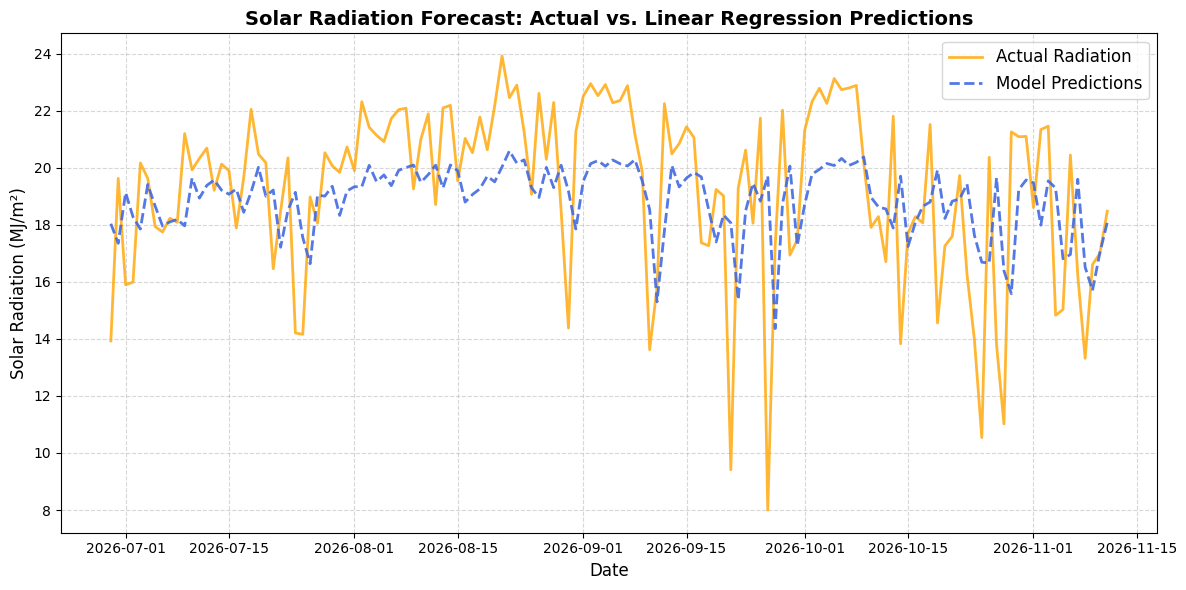

In [107]:
# Set up the plot size
plt.figure(figsize=(12, 6))

# Plot actual vs predicted radiation values over the test timeline
plt.plot(test_df['Day'], y_test, label='Actual Radiation', color='orange', alpha=0.8, linewidth=2)
plt.plot(test_df['Day'], model_preds, label='Model Predictions', color='royalblue', linestyle='--', alpha=0.9, linewidth=2)

# Add titles, labels, and legend
plt.xlabel('Date', fontsize=12)
plt.ylabel(f'{rad_col}', fontsize=12)
plt.title('Solar Radiation Forecast: Actual vs. Linear Regression Predictions', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.tight_layout()
plt.show()

## Step 7: Model Explainability (Feature Coefficients)
* **Why this matters:** Linear regression is a white-box model. Unlike a black-box neural network, we can look directly inside the math to see which weather features had the biggest impact on predicting tomorrow's solar radiation.
* **Our Strategy:** We extract and plot the model's coefficients to show whether variables like sunshine duration or temperature drive solar output up or down.

In [115]:
# Create a DataFrame to view each feature and its learned weight (coefficient)
coeff_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("📊 Feature Coefficients (Impact on Tomorrow's Radiation):")
print(coeff_df.to_string(index=False))

📊 Feature Coefficients (Impact on Tomorrow's Radiation):
                Feature  Coefficient
Solar Radiation (MJ/m²)     0.303322
       Temperature (°C)     0.051224
  Sunshine Duration (s)    -0.000027
     Precipitation (mm)    -0.071944


## Conclusion
* **What We Accomplished:** We successfully built an end-to-end solar radiation forecasting pipeline—from raw data cleaning and target engineering to chronological train/test splitting and baseline comparison.
* **Key Takeaway:** Our model successfully learned the mathematical patterns of weather drivers like sunshine duration and temperature, proving that data-driven AI beats naive persistence guesses.